In [ ]:
import sys

print("Python version:")
print(sys.version)

Python version:
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os

print("kaggle.json exists:",
      os.path.exists("/content/kaggle.json"))

kaggle.json exists: True


In [ ]:
import json
import os

path = "/content/kaggle.json"

with open(path, "r") as f:
    data = json.load(f)

print("Keys found:", list(data.keys()))
print("Username present:", bool(data.get("username")))
print("API key present:", bool(data.get("key")))

Keys found: ['username', 'key']
Username present: True
API key present: True


In [ ]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod(
    "/root/.kaggle/kaggle.json",
    0o600
)

print("Kaggle configuration completed.")
print(
    "Configured file exists:",
    os.path.exists("/root/.kaggle/kaggle.json")
)

Kaggle configuration completed.
Configured file exists: True


In [ ]:
import os

# Remove environment-variable authentication
os.environ.pop("KAGGLE_API_TOKEN", None)
os.environ.pop("KAGGLE_USERNAME", None)
os.environ.pop("KAGGLE_KEY", None)

# Remove OAuth access-token file if it exists
oauth_file = "/root/.kaggle/access_token"

if os.path.exists(oauth_file):
    os.remove(oauth_file)

print("Old/competing authentication methods cleared.")

Old/competing authentication methods cleared.


In [ ]:
!kaggle config view

Configuration values from /root/.kaggle
- username: lawmbb
- auth_method: LEGACY_API_KEY
- path: None
- proxy: None
- competition: None


In [ ]:
!kaggle datasets list -s "cats dogs"

ref                                                        title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
---------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
shaunthesheep/microsoft-catsvsdogs-dataset                 Cats-vs-Dogs                                         825979578  2020-03-12 05:34:30.730000         113203        995  0.875            
marquis03/cats-and-dogs                                    Cats and Dogs                                         10219362  2023-10-27 10:48:19.220000          18914        155  1                
chetankv/dogs-cats-images                                  Dogs & Cats Images                                   455718914  2018-04-19 18:20:08.593000          52336        620  0.5625           
mmoreaux/audio-cats-and-d

In [ ]:
!kaggle datasets download -d salader/dogsvscats

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [00:07<00:00, 155MB/s]



In [ ]:
import os

zip_path = "/content/dogsvscats.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print(
        "ZIP size:",
        round(os.path.getsize(zip_path) / (1024 * 1024), 2),
        "MB"
    )
else:
    print("ZIP was NOT downloaded.")

ZIP exists: True
ZIP size: 1089.85 MB


In [ ]:
!ls -lh /content

total 1.1G
-rw-r--r-- 1 root root 1.1G Oct 13  2019 dogsvscats.zip
-rw-r--r-- 1 root root   62 Sep 28 07:05 kaggle.json
drwxr-xr-x 1 root root 4.0K Sep 16 13:26 sample_data


In [ ]:
import zipfile
import os

zip_path = "/content/dogsvscats.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [ ]:
!find /content -maxdepth 2 -type d | head -30

/content
/content/.config
/content/.config/configurations
/content/.config/logs
/content/test
/content/test/dogs
/content/test/cats
/content/catsvsdogs
/content/catsvsdogs/test
/content/catsvsdogs/train
/content/train
/content/train/dogs
/content/train/cats
/content/sample_data


In [ ]:
#check train/test
import os

print("Train exists:", os.path.exists("/content/train"))
print("Test exists:", os.path.exists("/content/test"))

Train exists: True
Test exists: True


In [ ]:
#check the classes
print("Train folders:")

if os.path.exists("/content/train"):
    print(os.listdir("/content/train"))

print("\nTest folders:")

if os.path.exists("/content/test"):
    print(os.listdir("/content/test"))

Train folders:
['dogs', 'cats']

Test folders:
['dogs', 'cats']


In [ ]:
#count the image
import os

def count_images(folder):
    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

    total = 0

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(extensions):
                total += 1

    return total

print("Training images:",
      count_images("/content/train"))

print("Test images:",
      count_images("/content/test"))

Training images: 20000
Test images: 5000


In [ ]:
#check the GPU
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU devices: []


In [ ]:
#import libraries
import tensorflow as tf
from tensorflow import keras

from keras.models import Sequential
from keras.layers import (
    Dense,
    Conv2D,
    MaxPooling2D,
    Flatten,
    BatchNormalization,
    Dropout
)

import matplotlib.pyplot as plt
import cv2
import os

In [ ]:
#load training data
train_ds = keras.utils.image_dataset_from_directory(
    directory="/content/train",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

Found 20000 files belonging to 2 classes.


In [ ]:
#load validation data
validation_ds = keras.utils.image_dataset_from_directory(
    directory="/content/test",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

Found 5000 files belonging to 2 classes.


In [ ]:
#check class name
print("Class names:", train_ds.class_names)

Class names: ['cats', 'dogs']


In [ ]:
#normalize image
def process(image, label):
    image = tf.cast(image / 255.0, tf.float32)
    return image, label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [ ]:
#build CNN
model = Sequential()

# 1st Convolutional Block
model.add(
    Conv2D(
        32,
        kernel_size=(3, 3),
        padding="valid",
        activation="relu",
        input_shape=(256, 256, 3)
    )
)

model.add(BatchNormalization())

model.add(
    MaxPooling2D(
        pool_size=(2, 2),
        strides=2,
        padding="valid"
    )
)

# 2nd Convolutional Block
model.add(
    Conv2D(
        64,
        kernel_size=(3, 3),
        padding="valid",
        activation="relu"
    )
)

model.add(BatchNormalization())

model.add(
    MaxPooling2D(
        pool_size=(2, 2),
        strides=2,
        padding="valid"
    )
)

# 3rd Convolutional Block
model.add(
    Conv2D(
        128,
        kernel_size=(3, 3),
        padding="valid",
        activation="relu"
    )
)

model.add(BatchNormalization())

model.add(
    MaxPooling2D(
        pool_size=(2, 2),
        strides=2,
        padding="valid"
    )
)

# Flatten
model.add(Flatten())

# Fully connected layers
model.add(Dense(128, activation="relu"))
model.add(Dropout(0.1))

model.add(Dense(64, activation="relu"))
model.add(Dropout(0.1))

# Binary output
model.add(Dense(1, activation="sigmoid"))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
#compile
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
#Trian
history = model.fit(
    train_ds,
    epochs=10,
    validation_data=validation_ds
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2638s 4s/step - accuracy: 0.5813 - loss: 1.5891 - val_accuracy: 0.6516 - val_loss: 0.6318
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2659s 4s/step - accuracy: 0.7049 - loss: 0.5799 - val_accuracy: 0.7386 - val_loss: 0.5208
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2585s 4s/step - accuracy: 0.7624 - loss: 0.4997 - val_accuracy: 0.7418 - val_loss: 0.5130
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2572s 4s/step - accuracy: 0.8010 - loss: 0.4350 - val_accuracy: 0.7824 - val_loss: 0.4622
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2581s 4s/step - accuracy: 0.8382 - loss: 0.3674 - val_accuracy: 0.7944 - val_loss: 0.4718
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2591s 4s/step - accuracy: 0.8709 - loss: 0.3026 - val_accuracy: 0.8012 - val_loss: 0.5020
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2657s 4s/step - accuracy: 0.9089 - loss: 0.2231 - val_accuracy: 0.7560 - val_loss: 0.8032
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2659s 4s/step - accuracy: 0.9410 - loss: 0.1512 - 

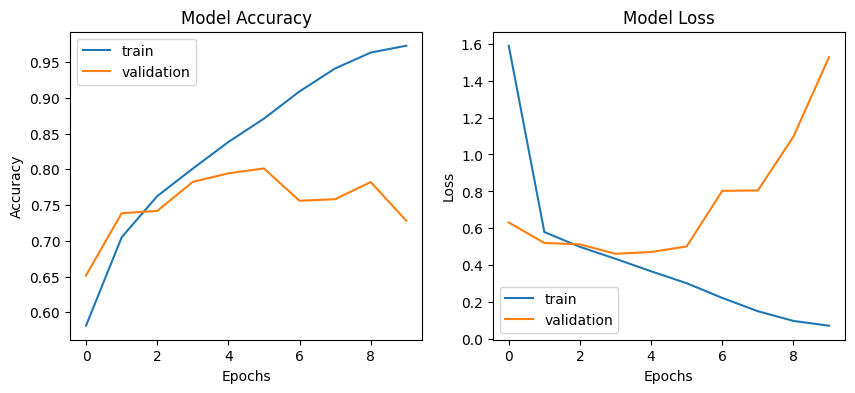

In [ ]:
#Plot accuracy and loss
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="train"
)

plt.plot(
    history.history["val_accuracy"],
    label="validation"
)

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="train"
)

plt.plot(
    history.history["val_loss"],
    label="validation"
)

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:
#upload own image
from google.colab import files

uploaded = files.upload()

Saving images (1).webp to images (1).webp


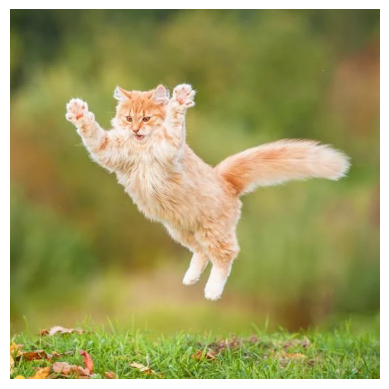

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
Raw Prediction Value: 1.7498234e-05
Prediction: CAT


In [ ]:
#prediction the image
import numpy as np
import cv2
import matplotlib.pyplot as plt

image_path = list(uploaded.keys())[0]

test_img = cv2.imread(image_path)

if test_img is None:
    print("Could not read the image.")
else:

    # OpenCV loads images as BGR
    test_img_rgb = cv2.cvtColor(
        test_img,
        cv2.COLOR_BGR2RGB
    )

    # Display original image
    plt.imshow(test_img_rgb)
    plt.axis("off")
    plt.show()

    # Resize
    test_img_resized = cv2.resize(
        test_img_rgb,
        (256, 256)
    )

    # Convert to NumPy array
    test_input = np.array(test_img_resized)

    # Add batch dimension
    test_input = test_input.reshape(
        (1, 256, 256, 3)
    )

    # Normalize
    test_input = test_input / 255.0

    # Prediction
    prediction = model.predict(test_input)

    probability = prediction[0][0]

    print("Raw Prediction Value:", probability)

    if probability < 0.5:
        print("Prediction: CAT")
    else:
        print("Prediction: DOG")